In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-darkgrid")
pd.set_option("display.float_format", "{:,.2f}".format)

# Funciona tanto si el notebook está en la raíz (junto a /data) como dentro de /data
DATA_DIR = Path("data") if Path("data").exists() else Path(".")
print(f"Usando directorio de trabajo: {DATA_DIR.resolve()}")

Usando directorio de trabajo: C:\Users\Priet\data


In [2]:
# Cargar dimensiones
dim_country = pd.read_csv(DATA_DIR / "dim_country.csv", keep_default_na=False)
dim_game = pd.read_csv(DATA_DIR / "dim_game.csv")
dim_player = pd.read_csv(DATA_DIR / "dim_player.csv")
dim_team = pd.read_csv(DATA_DIR / "dim_team.csv")
dim_year = pd.read_csv(DATA_DIR / "dim_year.csv")

# Cargar tablas de hechos (keep_default_na=False protege el código ISO 'NA' de Namibia)
f_country = pd.read_csv(
    DATA_DIR / "esports_country_earnings_by_year_clean.csv",
    keep_default_na=False,
)
f_game = pd.read_csv(DATA_DIR / "esports_game_earnings_by_year_clean.csv")
f_player = pd.read_csv(DATA_DIR / "esports_player_earnings_by_year_clean.csv")
f_team_game = pd.read_csv(
    DATA_DIR / "esports_team_earnings_by_game_clean.csv"
)
f_team_year = pd.read_csv(
    DATA_DIR / "esports_team_earnings_by_year_clean.csv"
)

# Enriquecer equipos por juego cruzando con dim_game
f_team_game_enriched = f_team_game.merge(dim_game, on="game_name", how="left")
f_team_game_enriched["genre"] = f_team_game_enriched["genre"].fillna(
    "Unclassified"
)

print(
    f"Archivos cargados correctamente. Periodo: {dim_year['year'].min()} -"
    f" {dim_year['year'].max()}"
)

Archivos cargados correctamente. Periodo: 1998 - 2024


In [3]:
print("=== ESTADÍSTICAS DESCRIPTIVAS: PREMIOS ANUALES POR JUEGO (USD) ===")
display(f_game[["total_earnings", "number_of_players", "number_of_tournaments"]].describe())

print("=== ESTADÍSTICAS DESCRIPTIVAS: PREMIOS ANUALES POR JUGADOR (USD) ===")
display(f_player[["total_year", "total_overall", "age"]].describe())

print("=== MATRIZ DE CORRELACIÓN (JUEGOS) ===")
display(f_game[["total_earnings", "number_of_players", "number_of_tournaments"]].corr())

=== ESTADÍSTICAS DESCRIPTIVAS: PREMIOS ANUALES POR JUEGO (USD) ===


,total_earnings,number_of_players,number_of_tournaments
count,"2,247.00","2,247.00","2,247.00"
mean,"872,868.01",133.83,30.70
std,"3,784,114.63",391.58,91.30
min,0.00,0.00,1.00
25%,"1,700.00",6.00,1.00
50%,"27,250.00",22.00,4.00
75%,"220,300.00",85.00,18.00
max,"80,807,759.01","4,838.00","1,026.00"


=== ESTADÍSTICAS DESCRIPTIVAS: PREMIOS ANUALES POR JUGADOR (USD) ===


,total_year,total_overall,age
count,"2,625.00","2,625.00","1,983.00"
mean,"197,453.34","709,778.31",33.90
std,"355,957.92","1,126,162.01",6.35
min,100.00,100.00,18.00
25%,"15,000.00","47,082.17",29.00
50%,"53,054.83","241,428.89",34.00
75%,"277,617.18","878,913.44",39.00
max,"3,696,652.43","7,184,163.05",62.00


=== MATRIZ DE CORRELACIÓN (JUEGOS) ===


,total_earnings,number_of_players,number_of_tournaments
total_earnings,1.00,0.67,0.44
number_of_players,0.67,1.00,0.75
number_of_tournaments,0.44,0.75,1.00


In [4]:
# 1. KPIs Anuales
kpi_year = (
    f_game.groupby("year")
    .agg(
        total_prize_pool_usd=("total_earnings", "sum"),
        total_active_players=("number_of_players", "sum"),
        total_tournaments=("number_of_tournaments", "sum"),
        active_games_count=("game_name", "nunique"),
    )
    .reset_index()
)

kpi_year["yoy_earnings_growth_pct"] = (
    kpi_year["total_prize_pool_usd"].pct_change() * 100
).round(2)
kpi_year["avg_prize_per_tournament_usd"] = (
    kpi_year["total_prize_pool_usd"] / kpi_year["total_tournaments"]
).round(2)
kpi_year["avg_prize_per_player_usd"] = (
    kpi_year["total_prize_pool_usd"] / kpi_year["total_active_players"]
).round(2)

# 2. KPIs por Género
kpi_genre = (
    f_game.groupby("genre")
    .agg(
        total_prize_pool_usd=("total_earnings", "sum"),
        total_tournaments=("number_of_tournaments", "sum"),
        total_players=("number_of_players", "sum"),
        unique_games=("game_name", "nunique"),
    )
    .reset_index()
    .sort_values("total_prize_pool_usd", ascending=False)
)

kpi_genre["market_share_pct"] = (
    kpi_genre["total_prize_pool_usd"]
    / kpi_genre["total_prize_pool_usd"].sum()
    * 100
).round(2)
kpi_genre["avg_prize_per_tournament_usd"] = (
    kpi_genre["total_prize_pool_usd"] / kpi_genre["total_tournaments"]
).round(2)

# 3. Perfil de Diversificación de Equipos
kpi_team = (
    f_team_game_enriched.groupby(["team_website_id", "team_name"])
    .agg(
        total_earnings_usd=("team_total_earnings", "sum"),
        games_competed=("game_name", "nunique"),
        genres_competed=("genre", "nunique"),
        top_game=("game_name", "first"),
        top_game_earnings=("team_total_earnings", "first"),
    )
    .reset_index()
    .sort_values("total_earnings_usd", ascending=False)
)

kpi_team["top_game_dependency_pct"] = (
    kpi_team["top_game_earnings"] / kpi_team["total_earnings_usd"] * 100
).round(2)

# Exportar los 3 archivos en la misma carpeta
kpi_year.to_csv(DATA_DIR / "kpi_summary_by_year.csv", index=False)
kpi_genre.to_csv(DATA_DIR / "kpi_summary_by_genre.csv", index=False)
kpi_team.to_csv(DATA_DIR / "team_diversification_profile.csv", index=False)

print("Tablas de KPIs guardadas en:", DATA_DIR.resolve())
display(kpi_year.tail(5))

Tablas de KPIs guardadas en: C:\Users\Priet\data


,year,total_prize_pool_usd,total_active_players,total_tournaments,active_games_count,yoy_earnings_growth_pct,avg_prize_per_tournament_usd,avg_prize_per_player_usd
22,2020,"153,398,625.30",30869,6278,226,-40.59,"24,434.31","4,969.34"
23,2021,"262,302,956.11",32910,6550,209,70.99,"40,046.25","7,970.31"
24,2022,"260,970,493.33",33097,6244,172,-0.51,"41,795.40","7,885.02"
25,2023,"233,655,046.09",31814,5170,133,-10.47,"45,194.40","7,344.41"
26,2024,"195,414,475.37",23634,3728,115,-16.37,"52,418.05","8,268.36"


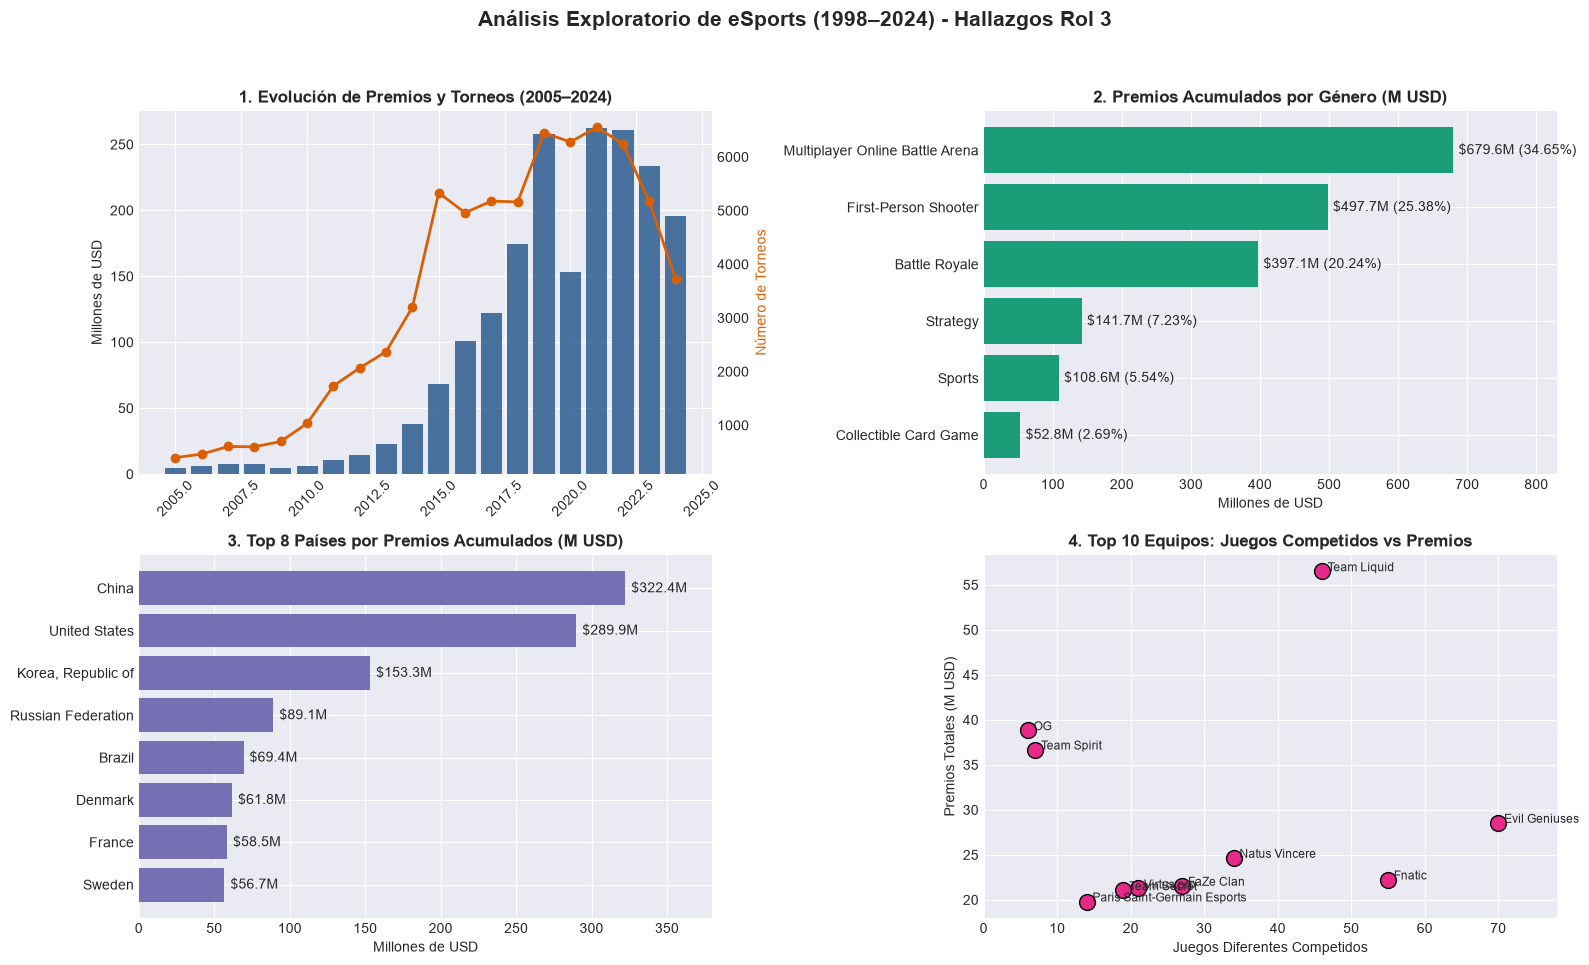

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    "Análisis Exploratorio de eSports (1998–2024) - Hallazgos Rol 3",
    fontsize=15,
    fontweight="bold",
)

# Gráfica 1: Serie Temporal (2005-2024)
sub_y = kpi_year[kpi_year["year"] >= 2005]
ax1 = axes[0, 0]
ax1.bar(
    sub_y["year"],
    sub_y["total_prize_pool_usd"] / 1e6,
    color="#2b5c8f",
    alpha=0.85,
)
ax1.set_title(
    "1. Evolución de Premios y Torneos (2005–2024)", fontweight="bold"
)
ax1.set_ylabel("Millones de USD")
ax1.tick_params(axis="x", rotation=45)

ax1_t = ax1.twinx()
ax1_t.plot(
    sub_y["year"],
    sub_y["total_tournaments"],
    color="#d95f02",
    marker="o",
    linewidth=2,
)
ax1_t.set_ylabel("Número de Torneos", color="#d95f02")
ax1_t.grid(False)

# Gráfica 2: Top 6 Géneros
ax2 = axes[0, 1]
top_g = kpi_genre.head(6).sort_values("total_prize_pool_usd", ascending=True)
ax2.barh(top_g["genre"], top_g["total_prize_pool_usd"] / 1e6, color="#1b9e77")
ax2.set_title("2. Premios Acumulados por Género (M USD)", fontweight="bold")
ax2.set_xlabel("Millones de USD")
for i, (_, row) in enumerate(top_g.iterrows()):
    val = row["total_prize_pool_usd"] / 1e6
    ax2.text(
        val + 8, i, f"${val:.1f}M ({row['market_share_pct']}%)", va="center"
    )
ax2.set_xlim(0, 830)

# Gráfica 3: Top 8 Países
ax3 = axes[1, 0]
top_c = (
    f_country.groupby("country_name")["total_earnings"]
    .sum()
    .sort_values(ascending=True)
    .tail(8)
)
ax3.barh(top_c.index, top_c.values / 1e6, color="#7570b3")
ax3.set_title("3. Top 8 Países por Premios Acumulados (M USD)", fontweight="bold")
ax3.set_xlabel("Millones de USD")
for i, v in enumerate(top_c.values / 1e6):
    ax3.text(v + 4, i, f"${v:.1f}M", va="center")
ax3.set_xlim(0, 380)

# Gráfica 4: Diversificación vs Especialización (Top 10 Equipos)
ax4 = axes[1, 1]
top_t = kpi_team.head(10)
ax4.scatter(
    top_t["games_competed"],
    top_t["total_earnings_usd"] / 1e6,
    s=130,
    color="#e7298a",
    edgecolors="black",
)
for _, row in top_t.iterrows():
    ax4.annotate(
        row["team_name"],
        (row["games_competed"] + 0.8, row["total_earnings_usd"] / 1e6),
        fontsize=8.5,
    )
ax4.set_title(
    "4. Top 10 Equipos: Juegos Competidos vs Premios", fontweight="bold"
)
ax4.set_xlabel("Juegos Diferentes Competidos")
ax4.set_ylabel("Premios Totales (M USD)")
ax4.set_xlim(0, 78)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.savefig(DATA_DIR / "rol3_eda_dashboard_summary.png", dpi=300)
plt.show()

In [6]:
import numpy as np
import plotly.express as px

# 1. Agrupar datos históricos por país
country_map_df = (
    f_country.groupby(["country_code", "country_name"])
    .agg(
        total_earnings_usd=("total_earnings", "sum"),
        total_player_records=("number_of_players", "sum"),
        years_active=("year", "nunique"),
        best_rank=("rank", "min"),
    )
    .reset_index()
)

# 2. Columna en escala logarítmica para iluminar todos los países con contraste
country_map_df["log_earnings"] = np.log10(
    country_map_df["total_earnings_usd"].clip(lower=1)
)

# 3. Construir mapa mundial iluminado (Dark Mode + Neón Plasma)
fig = px.choropleth(
    country_map_df,
    locations="country_name",
    locationmode="country names",
    color="log_earnings",
    hover_name="country_name",
    hover_data={
        "log_earnings": False,
        "country_code": True,
        "total_earnings_usd": ":$,.2f",
        "total_player_records": ":,",
        "years_active": True,
        "best_rank": True,
    },
    color_continuous_scale="Plasma",
    title="Mapa Global Iluminado de Premios en eSports por País (1998–2024)",
)

# 4. Estilo oscuro e iluminación de fronteras
fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#060913",
    plot_bgcolor="#060913",
    geo=dict(
        bgcolor="#060913",
        showframe=False,
        showcoastlines=True,
        coastlinecolor="#38bdf8",
        showland=True,
        landcolor="#111827",
        showocean=True,
        oceancolor="#060913",
        projection_type="natural earth",
    ),
    coloraxis_colorbar=dict(
        title="Premios (USD)",
        tickvals=[2, 3, 4, 5, 6, 7, 8],
        ticktext=["$100", "$1K", "$10K", "$100K", "$1M", "$10M", "$100M+"],
    ),
    margin=dict(l=10, r=10, t=55, b=10),
    height=620,
)

# Guardar versión interactiva en HTML y mostrar en Jupyter
fig.write_html(DATA_DIR / "mapa_mundial_esports_interactivo.html")
fig.show()

ModuleNotFoundError: No module named 'plotly'

In [7]:
%pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 4.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.7 MB 4.4 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/9.7 MB 5.3 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.7 MB 5.5 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.7 MB 6.3 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.7 MB 6.2 MB/s eta 0:00:01
   --------------------------------- ------ 8.1/9.7 MB 6.0 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.7 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 5.6 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Priet\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [8]:
import numpy as np
import plotly.express as px

# 1. Agrupar datos históricos por país
country_map_df = (
    f_country.groupby(["country_code", "country_name"])
    .agg(
        total_earnings_usd=("total_earnings", "sum"),
        total_player_records=("number_of_players", "sum"),
        years_active=("year", "nunique"),
        best_rank=("rank", "min"),
    )
    .reset_index()
)

# 2. Columna en escala logarítmica para iluminar todos los países con contraste
country_map_df["log_earnings"] = np.log10(
    country_map_df["total_earnings_usd"].clip(lower=1)
)

# 3. Construir mapa mundial iluminado (Dark Mode + Neón Plasma)
fig = px.choropleth(
    country_map_df,
    locations="country_name",
    locationmode="country names",
    color="log_earnings",
    hover_name="country_name",
    hover_data={
        "log_earnings": False,
        "country_code": True,
        "total_earnings_usd": ":$,.2f",
        "total_player_records": ":,",
        "years_active": True,
        "best_rank": True,
    },
    color_continuous_scale="Plasma",
    title="Mapa Global Iluminado de Premios en eSports por País (1998–2024)",
)

# 4. Estilo oscuro e iluminación de fronteras
fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#060913",
    plot_bgcolor="#060913",
    geo=dict(
        bgcolor="#060913",
        showframe=False,
        showcoastlines=True,
        coastlinecolor="#38bdf8",
        showland=True,
        landcolor="#111827",
        showocean=True,
        oceancolor="#060913",
        projection_type="natural earth",
    ),
    coloraxis_colorbar=dict(
        title="Premios (USD)",
        tickvals=[2, 3, 4, 5, 6, 7, 8],
        ticktext=["$100", "$1K", "$10K", "$100K", "$1M", "$10M", "$100M+"],
    ),
    margin=dict(l=10, r=10, t=55, b=10),
    height=620,
)

# Guardar versión interactiva en HTML y mostrar en Jupyter
fig.write_html(DATA_DIR / "mapa_mundial_esports_interactivo.html")
fig.show()

In [ ]:
import json
import urllib.request
from matplotlib.collections import PatchCollection
import matplotlib.colors as mcolors
from matplotlib.patches import Polygon
import matplotlib.pyplot as plt
import numpy as np

# 1. Descargar geometría mundial ligera (Natural Earth 110m GeoJSON)
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
with urllib.request.urlopen(url) as response:
    world_geo = json.loads(response.read().decode("utf-8"))

# 2. Preparar diccionario de premios por código ISO-2 (ej. 'US', 'CN', 'MX')
earnings_by_iso2 = (
    f_country.groupby("country_code")["total_earnings"].sum().to_dict()
)

# 3. Configurar figura estilo Dark Mode / Iluminado
fig, ax = plt.subplots(figsize=(18, 9.5), facecolor="#060913")
ax.set_facecolor("#060913")

cmap = plt.cm.plasma
norm = mcolors.LogNorm(vmin=100, vmax=max(earnings_by_iso2.values()))

patches = []
colors = []
edge_colors = []
line_widths = []

for feature in world_geo["features"]:
    props = feature["properties"]
    # Obtener código ISO-2 estándar
    iso2 = props.get("ISO_A2")
    if iso2 == "-99":
        iso2 = props.get("ISO_A2_EH", "")
    if props.get("ADMIN") == "Antarctica":
        continue

    val = earnings_by_iso2.get(iso2, 0)
    geom = feature["geometry"]
    polys = (
        [geom["coordinates"]]
        if geom["type"] == "Polygon"
        else geom["coordinates"]
    )

    for poly in polys:
        ring = np.array(poly[0])
        patches.append(Polygon(ring, closed=True))
        if val > 0:
            colors.append(cmap(norm(max(val, 100))))
            edge_colors.append("#38bdf8")
            line_widths.append(0.75)
        else:
            colors.append("#111827")
            edge_colors.append("#1e293b")
            line_widths.append(0.5)

collection = PatchCollection(
    patches,
    facecolors=colors,
    edgecolors=edge_colors,
    linewidths=line_widths,
)
ax.add_collection(collection)

# Ajustar límites del mapa
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 85)
ax.set_aspect("equal")

# Barra de color
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm._A = []
cbar = fig.colorbar(sm, ax=ax, fraction=0.023, pad=0.015, aspect=28)
cbar.set_label(
    "Premios Acumulados (USD - Escala Logarítmica)",
    color="#e2e8f0",
    fontsize=11,
    fontweight="bold",
)
cbar.ax.yaxis.set_tick_params(color="#e2e8f0", labelcolor="#e2e8f0")
cbar.outline.set_edgecolor("#334155")

# Etiquetas destacadas (Top 5 Mundial + México)
highlights = [
    (104, 35, 104, 35, "China\n$322.4M"),
    (-98, 39, -98, 39, "EE. UU.\n$289.9M"),
    (127.8, 36.5, 148, 25, "Corea del Sur\n$153.3M"),
    (95, 62, 95, 62, "Rusia\n$89.1M"),
    (-52, -10, -52, -10, "Brasil\n$69.4M"),
    (-102, 23.5, -120, 12, "México\n$10.3M"),
]

for x, y, tx, ty, label in highlights:
    ax.annotate(
        label,
        xy=(x, y),
        xytext=(tx, ty),
        color="#ffffff",
        fontsize=8.5,
        fontweight="bold",
        ha="center",
        va="center",
        arrowprops=dict(arrowstyle="-", color="#38bdf8", lw=0.9)
        if (x != tx or y != ty)
        else None,
        bbox=dict(
            boxstyle="round,pad=0.28",
            facecolor="#0f172a",
            edgecolor="#38bdf8",
            alpha=0.9,
            lw=0.9,
        ),
    )

ax.set_title(
    "Mapa Global Iluminado de Premios en eSports por País (1998–2024)\nTotal"
    " Acumulado por Nacionalidad: $1,875.6M USD",
    color="#f8fafc",
    fontsize=16,
    fontweight="bold",
    pad=14,
)
ax.set_axis_off()

plt.tight_layout()
plt.savefig(
    DATA_DIR / "mapa_mundial_esports_iluminado.png",
    dpi=300,
    facecolor="#060913",
)
plt.show()